# 05 Horizon strategies

**Decision:** how should one model produce forecasts for 1 to 14 weeks ahead?

The lag features that make a model accurate one week ahead are not observed further out. Each strategy handles that differently. Same data, scaler, LightGBM parameters and evaluation rows; only the strategy changes.

1. Feature availability
2. Three forecasting strategies
3. Backtesting results

Runs in about two minutes.

In [7]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [8]:
import time

import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard, breakdown

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]

## 1. Feature availability

Standing at the cutoff, the lag-*k* value for a target *h* weeks ahead is observed only if *k* is at least *h*. Otherwise it refers to a week that has not happened yet.

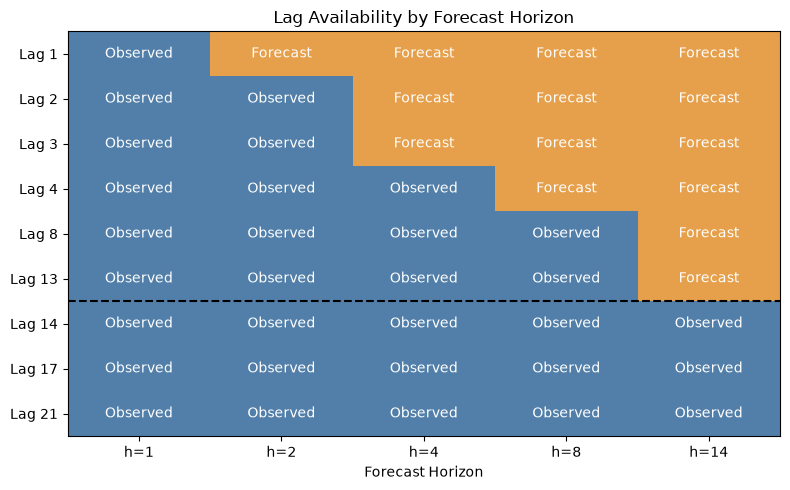

In [9]:
lags = [1, 2, 3, 4, 8, 13, 14, 17, 21]
horizons = [1, 2, 4, 8, 14]

availability = np.array([
    [int(k >= h) for h in horizons]
    for k in lags
])

fig, ax = plt.subplots(figsize=(8, 5))

ax.imshow(
    availability,
    cmap=ListedColormap(["#e6a04b", "#527fa9"]),
    aspect="auto",
    vmin=0, vmax=1
)

ax.set_xticks(range(len(horizons)), [f"h={h}" for h in horizons])
ax.set_yticks(range(len(lags)), [f"Lag {k}" for k in lags])

for i, k in enumerate(lags):
    for j, h in enumerate(horizons):
        ax.text(j, i, "Observed" if k >= h else "Forecast",
                ha="center", va="center", color="white")

ax.axhline(lags.index(14) - 0.5, color="black", linestyle="--")
ax.set_title("Lag Availability by Forecast Horizon")
ax.set_xlabel("Forecast Horizon")

plt.tight_layout()
plt.show()

The model of notebook 02 uses lags 1, 2, 3, 4, 8 and 13 and rolling means of lag 1. One week ahead, all are observed. Fourteen weeks ahead, none are: every one of them refers to a week inside the forecast window.

## 2. Three forecasting strategies

| strategy | models per cutoff | target lags | how week *h* is reached |
|---|---|---|---|
| recursive | 1 | 1 to 13 | predict week 1, feed the prediction back into the lags, predict week 2, and so on |
| direct | 14 | 1 to 13, measured from the cutoff | model *h* predicts week *h* from features observed at the cutoff |
| horizon-safe | 1 | 14 to 26 | every lag is observed for all 14 weeks, so nothing is fed back |

Recursive and direct use the **same constructor**. The difference is one argument at fit time: `fit(train, max_horizon=H)` trains a separate model for each horizon. The horizon-safe model differs in its constructor: its lags and rolling means start at lag 14.

In [10]:
# recursive: the notebook 02 baseline
# 1 MODEL
mlf_recursive = MLForecast(
    models={"lgbm_recursive": lgb.LGBMRegressor(**LGB_PARAMS)},
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)

# direct: the same constructor; fit(..., max_horizon=H) trains one model per horizon
# 14 MODELS
mlf_direct = MLForecast(
    models={"lgbm_direct": lgb.LGBMRegressor(**LGB_PARAMS)},
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)

# horizon-safe: every lag and rolling mean starts at lag 14
# 1 MODEL
mlf_safe = MLForecast(
    models={"lgbm_horizon_safe": lgb.LGBMRegressor(**LGB_PARAMS)},
    freq=FREQ,
    lags=[14, 15, 16, 17, 21, 26],
    lag_transforms={14: [RollingMean(window_size=4), RollingMean(window_size=13), RollingMean(window_size=26)]},
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)

The horizon-safe model is still **a single model**, like the recursive one. Unlike the recursive model, it never depends on its own earlier predictions within the 14-week horizon. The price is that it never sees the most recent 13 weeks of sales.

**Multi-output** models are a fourth strategy: one model that outputs all 14 weeks at once, sharing what it learns across horizons. Tree models such as LightGBM predict one value per model, so they need the direct approach for that. The neural models of Day 2 (NHITS, TFT and others) are multi-output by design.

## 3. Backtesting results

All three strategies at every cutoff. The recursive model has the configuration of `lgbm_baseline` from notebook 02 and reproduces its forecasts. The fit time of each strategy is recorded for the appendix.

<B> Notice the extra parameter in direct </B>

In [11]:
forecasts, fit_seconds = [], {"recursive": 0.0, "direct": 0.0, "horizon_safe": 0.0}
for cutoff in ALL_CUTOFFS:
    train = actuals[actuals.ds <= cutoff]

    start = time.perf_counter()
    mlf_recursive.fit(train)
    forecasts.append(to_long(mlf_recursive.predict(H), cutoff, "05_horizon_strategies"))
    fit_seconds["recursive"] += time.perf_counter() - start

    start = time.perf_counter()
    mlf_direct.fit(train, max_horizon=H)
    forecasts.append(to_long(mlf_direct.predict(H), cutoff, "05_horizon_strategies"))
    fit_seconds["direct"] += time.perf_counter() - start

    start = time.perf_counter()
    mlf_safe.fit(train)
    forecasts.append(to_long(mlf_safe.predict(H), cutoff, "05_horizon_strategies"))
    fit_seconds["horizon_safe"] += time.perf_counter() - start

forecasts = pd.concat(forecasts)

HistoricAverage from notebook 01 is the reference. Development WAPE, bias, mean RMSSE and APC come from the seven development cutoffs; final WAPE is the final 14 weeks (exploratory).

In [12]:
reference = load_forecasts(["01_baselines"]).query("model == 'HistoricAverage'")
candidates = pd.concat([reference, forecasts])

dev = leaderboard(candidates, actuals, scope="dev").set_index("model")
final = leaderboard(candidates, actuals, scope="test").set_index("model")
pd.DataFrame({
    "dev_wape": dev.wape,
    "final_wape": final.wape,
    "dev_bias": dev.bias,
    "dev_mean_rmsse": dev.mean_rmsse,
    "dev_apc": dev.apc,
}).loc[["HistoricAverage", "lgbm_recursive", "lgbm_direct", "lgbm_horizon_safe"]].round(3)

,dev_wape,final_wape,dev_bias,dev_mean_rmsse,dev_apc
model,,,,,
HistoricAverage,0.426,0.426,-0.061,1.791,0.019
lgbm_recursive,0.449,0.419,0.139,1.865,0.136
lgbm_direct,0.398,0.380,-0.033,1.765,0.150
lgbm_horizon_safe,0.427,0.416,-0.012,1.806,0.099


### By horizon

Development cutoffs, the same rows for every model. Horizon 1 is the first week after the cutoff.

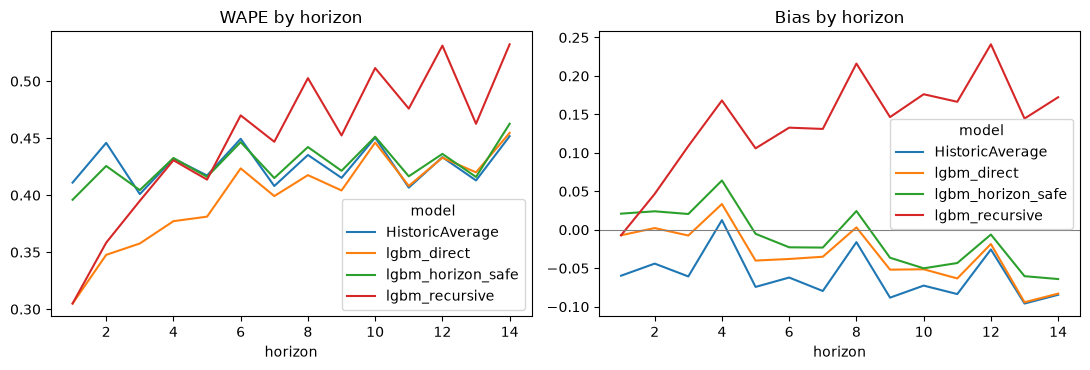

In [13]:
by_horizon = breakdown(candidates, actuals, "horizon", scope="dev")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_horizon.pivot(index="horizon", columns="model", values="wape").plot(ax=axes[0], title="WAPE by horizon")
by_horizon.pivot(index="horizon", columns="model", values="bias").plot(ax=axes[1], title="Bias by horizon")
axes[1].axhline(0, color="grey", lw=0.8)
plt.tight_layout()

### Reading the result

- **Direct is the most accurate.** Development WAPE 0.398 and final 0.380, with a small bias (-0.033). It is the only strategy here that beats HistoricAverage on development WAPE.
- **Recursive errors grow with the horizon.** At horizon 1, recursive and direct solve the same problem. Further out, the recursive model reads its own forecasts as lags, and its overforecast compounds: bias +0.139 overall.
- **Horizon-safe is nearly flat across horizons**, with almost no bias and the most stable forecasts. It never sees the most recent 13 weeks, so it gives up accuracy at short horizons and lands at about the level of HistoricAverage.

| | recursive | direct | horizon-safe |
|---|---|---|---|
| accuracy (development WAPE) | 0.449 | **0.398** | 0.427 |
| recent information | lags 1 to 13, predicted after week 1 | lags 1 to 13, all observed at the cutoff | nothing from the last 13 weeks |
| stability (development APC) | 0.136 | 0.150 | **0.099** |
| cost per cutoff | 1 model | 14 models, about 10 times the training time | 1 model |

In [14]:
save_forecasts(forecasts[forecasts.model != "lgbm_recursive"], "05_horizon_strategies")

## Training cost

Seconds to fit and forecast 14 weeks for 2,000 series on one CPU thread, summed over the ten cutoffs of the backtest above.

In [15]:
pd.Series(fit_seconds, name="seconds_all_cutoffs").round(1).to_frame().assign(models_per_cutoff=[1, H, 1])

,seconds_all_cutoffs,models_per_cutoff
recursive,6.5,1
direct,58.1,14
horizon_safe,4.9,1
